---
title: "Coupled Oscillators and Normal Modes — Level 2"
short_title: "10 Normal Modes"
numbering:
  heading_2: true
  equation: true
---

# Coupled Oscillators and Normal Modes

:::{seealso} Math for this topic
- [M6: Linear algebra](../math/06-linear-algebra.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca (touched in waves) | Single oscillators only; coupling appears informally as waves |
| **2** | **Taylor, ch. 11** | **Set up the eigenvalue problem (K − ω²M)a = 0 and find normal modes** |
| 3 | Goldstein, ch. 6 | General small-oscillation theory, normal coordinates, degenerate modes |

The new skill at this level: turning a coupled set of equations into independent oscillators by finding the right coordinates

Math for this topic: M6, linear algebra (eigenvalues, generalized eigenproblem, systems of linear ODEs).
:::

Builds on the oscillations notes and the Lagrangian notes. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Two Coupled Carts

Two carts of mass $m$ sit on a frictionless track between two walls, connected wall–cart–cart–wall by three springs of stiffness $k$. With $x_1, x_2$ the displacements from equilibrium,

$$
m\ddot x_1 = -2kx_1 + kx_2, \qquad m\ddot x_2 = kx_1 - 2kx_2 ,
$$

or in matrix form

$$
M\ddot{\vec{x}} = -K\vec{x}, \qquad M = \begin{pmatrix}m & 0\\ 0 & m\end{pmatrix}, \quad K = \begin{pmatrix}2k & -k\\ -k & 2k\end{pmatrix} .
$$ (eq-mk)

The middle spring **couples** the equations. Look for a motion in which both carts oscillate at the same frequency, $\vec{x} = \operatorname{Re}\big(\vec{a}\,e^{i\omega t}\big)$. Substituting gives

$$
\left(K - \omega^2M\right)\vec{a} = \vec{0} ,
$$ (eq-normal-mode)

the generalized eigenvalue problem from M6. A nonzero $\vec{a}$ requires $\det(K - \omega^2M) = 0$, which here is $(2k - m\omega^2)^2 - k^2 = 0$:

| Mode | Frequency | Shape $\vec{a}$ | Motion |
|---|---|---|---|
| 1 | $\omega_1 = \sqrt{k/m}$ | $\langle1, 1\rangle$ | carts move together; middle spring never stretches |
| 2 | $\omega_2 = \sqrt{3k/m}$ | $\langle1, -1\rangle$ | carts move oppositely; middle spring works hard |

These are the **normal modes**: patterns of motion in which every part oscillates at one frequency. The general motion is a superposition,

$$
\vec{x}(t) = A_1\begin{pmatrix}1\\1\end{pmatrix}\cos(\omega_1t - \delta_1) + A_2\begin{pmatrix}1\\-1\end{pmatrix}\cos(\omega_2t - \delta_2) ,
$$

with four constants fixed by the initial positions and velocities.

In [2]:
# The same eigenproblem, symbolically
m, k, w2 = sp.symbols("m k omega2", positive=True)
M = sp.diag(m, m)
K = sp.Matrix([[2 * k, -k], [-k, 2 * k]])
print("det condition:", sp.factor((K - w2 * M).det()))
for val in sp.solve((K - w2 * M).det(), w2):
    print("omega^2 =", val, " mode:", (K - val * M).nullspace()[0].T)

det condition: (k - m*omega2)*(3*k - m*omega2)
omega^2 = k/m  mode: Matrix([[1, 1]])
omega^2 = 3*k/m  mode: Matrix([[-1, 1]])


### Normal coordinates

Define $\xi_1 = \tfrac12(x_1 + x_2)$ and $\xi_2 = \tfrac12(x_1 - x_2)$. Adding and subtracting the equations of motion gives

$$
\ddot\xi_1 = -\omega_1^2\xi_1, \qquad \ddot\xi_2 = -\omega_2^2\xi_2 .
$$

In these **normal coordinates** the system is two independent simple harmonic oscillators. Finding normal modes is exactly finding the coordinates that decouple the equations, the eigenvector basis of M6.

### Weak coupling and beats

Replace the middle spring by a weak one, $k'\ll k$. Then $\omega_1 = \sqrt{k/m}$ and $\omega_2 = \sqrt{(k + 2k')/m}$ are close. Start cart 1 moving and cart 2 at rest: that is an equal mix of both modes, and as they drift out of phase the energy sloshes back and forth between the carts at the **beat** period $2\pi/(\omega_2 - \omega_1)$. Two pendulums hanging from a slightly flexible bar do the same thing.

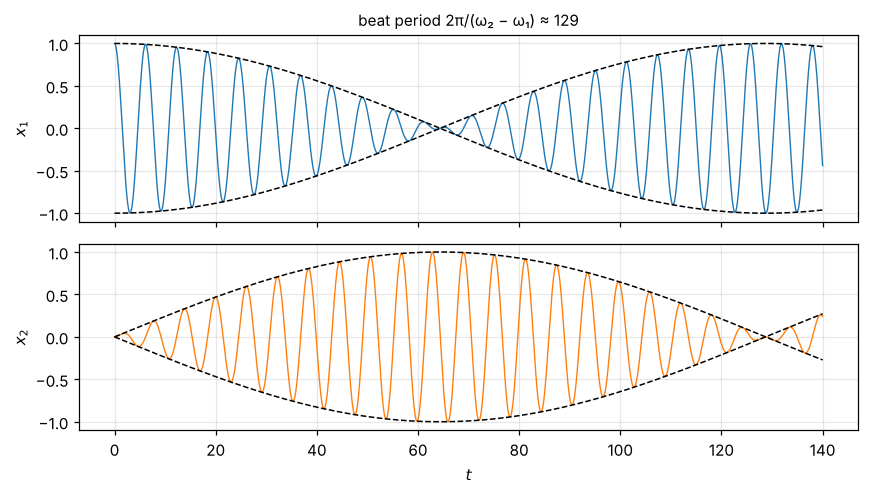

In [3]:
#| label: fig-beats
#| caption: Weakly coupled carts (k′ = 0.05k). Cart 1 starts displaced and cart 2 at rest. Energy passes completely back and forth between them at the beat period (dashed envelopes).
m_, k_, kp = 1.0, 1.0, 0.05
w1, w2 = np.sqrt(k_ / m_), np.sqrt((k_ + 2 * kp) / m_)
t = np.linspace(0, 140, 5000)
x1 = 0.5 * (np.cos(w1 * t) + np.cos(w2 * t))
x2 = 0.5 * (np.cos(w1 * t) - np.cos(w2 * t))
env = np.abs(np.cos(0.5 * (w2 - w1) * t)); env2 = np.abs(np.sin(0.5 * (w2 - w1) * t))
fig, axes = plt.subplots(2, 1, figsize=(8, 4.6), sharex=True)
axes[0].plot(t, x1, lw=0.9); axes[0].plot(t, env, "k--", lw=1); axes[0].plot(t, -env, "k--", lw=1)
axes[1].plot(t, x2, lw=0.9, color="tab:orange"); axes[1].plot(t, env2, "k--", lw=1); axes[1].plot(t, -env2, "k--", lw=1)
axes[0].set_ylabel("$x_1$"); axes[1].set_ylabel("$x_2$"); axes[1].set_xlabel("$t$")
axes[0].set_title(f"beat period 2π/(ω₂ − ω₁) ≈ {2 * np.pi / (w2 - w1):.0f}", fontsize=10)
plt.tight_layout(); plt.show()

## The General Method

Any system with $n$ degrees of freedom near a stable equilibrium has, to second order in the displacements $\vec{q}$,

$$
T = \tfrac12\,\dot{\vec{q}}^{\mathsf T}M\,\dot{\vec{q}}, \qquad U = \tfrac12\,\vec{q}^{\mathsf T}K\,\vec{q} ,
$$

with $M$ (the mass matrix) and $K$ (the stiffness matrix, the Hessian of $U$ from M3) both symmetric. Lagrange's equations give $M\ddot{\vec{q}} = -K\vec{q}$, and the recipe is always the same:

1. Find $M$ and $K$ (expand $T$ and $U$ to second order about equilibrium).
2. Solve $\det(K - \omega^2M) = 0$ for the $n$ normal frequencies.
3. Solve $(K - \omega_r^2M)\vec{a}_r = \vec{0}$ for each mode shape.
4. Superpose the modes to fit initial conditions.

The mode shapes are orthogonal with respect to $M$, so the initial conditions decompose cleanly onto them. If $K$ has a zero eigenvalue, the corresponding "mode" is not an oscillation but a free motion (for example, a molecule translating or rotating as a whole).

::::{prf:example} The double pendulum
:label: ex-double-pendulum

Two equal masses $m$ hang on two massless rods of length $L$, one below the other. Find the normal modes for small swings.

:::{dropdown} Solution
With angles $\phi_1, \phi_2$ from the vertical, expanding $T$ and $U$ to second order gives

$$
M = mL^2\begin{pmatrix}2 & 1\\ 1 & 1\end{pmatrix}, \qquad K = mgL\begin{pmatrix}2 & 0\\ 0 & 1\end{pmatrix} .
$$

Here the coupling is in the mass matrix (the upper rod's motion carries the lower mass along), not in a spring. Then $\det(K - \omega^2M) = 0$ gives

$$
\omega^2 = \frac gL\left(2\mp\sqrt2\right) .
$$

The slow mode has $\phi_2 = \sqrt2\,\phi_1$ (both swing the same way, lower one farther); the fast mode has $\phi_2 = -\sqrt2\,\phi_1$ (they swing oppositely).
:::
::::

In [4]:
# Double pendulum: build M and K from the full Lagrangian, then solve the eigenproblem
t = sp.symbols("t"); mm, LL, gg = sp.symbols("m L g", positive=True)
p1, p2 = sp.Function("phi1")(t), sp.Function("phi2")(t)
x1, y1 = LL * sp.sin(p1), -LL * sp.cos(p1)
x2, y2 = x1 + LL * sp.sin(p2), y1 - LL * sp.cos(p2)
T = sp.Rational(1, 2) * mm * (x1.diff(t)**2 + y1.diff(t)**2 + x2.diff(t)**2 + y2.diff(t)**2)
U = mm * gg * (y1 + y2)
q, qd = [p1, p2], [p1.diff(t), p2.diff(t)]
Mmat = sp.Matrix(2, 2, lambda i, j: sp.diff(T, qd[i], qd[j])).subs({p1: 0, p2: 0})
Kmat = sp.Matrix(2, 2, lambda i, j: sp.diff(U, q[i], q[j])).subs({p1: 0, p2: 0})
print("M =", sp.simplify(Mmat)); print("K =", sp.simplify(Kmat))
w2s = sp.solve((Kmat - sp.Symbol("w2") * Mmat).det(), sp.Symbol("w2"))
print("omega^2 =", [sp.simplify(w) for w in w2s])

M = Matrix([[2*L**2*m, L**2*m], [L**2*m, L**2*m]])
K = Matrix([[2*L*g*m, 0], [0, L*g*m]])
omega^2 = [g*(2 - sqrt(2))/L, g*(sqrt(2) + 2)/L]


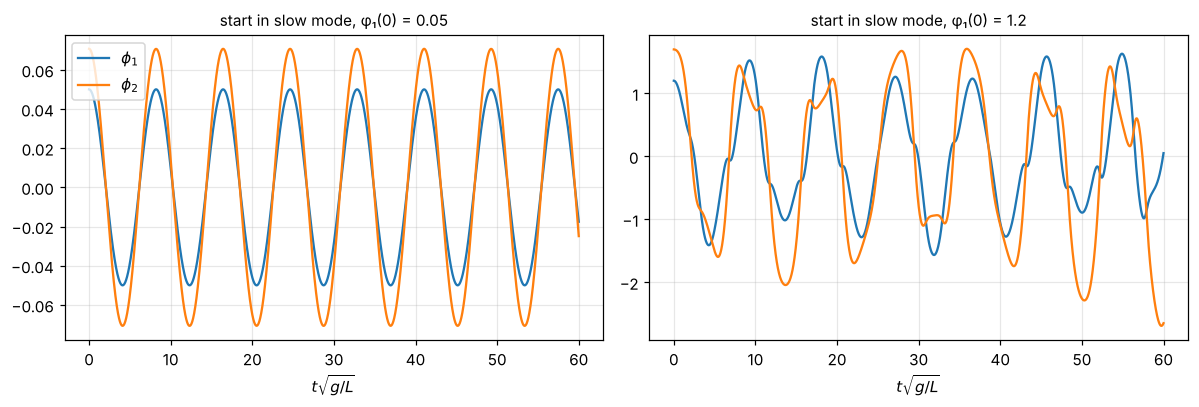

In [5]:
#| label: fig-double-pendulum-modes
#| caption: The full nonlinear double pendulum started in its slow normal mode (φ₂ = √2 φ₁). At small amplitude (left) both angles stay locked in that pattern at a single frequency; at large amplitude (right) the mode breaks up and the motion becomes irregular.
gL = 1.0
def rhs(s, y):
    a, b, ad, bd = y
    dlt = a - b
    den = 2 - np.cos(dlt)**2
    add = (-np.sin(dlt) * (bd**2 + ad**2 * np.cos(dlt)) - gL * (2 * np.sin(a) - np.sin(b) * np.cos(dlt))) / den
    bdd = (np.sin(dlt) * (2 * ad**2 + bd**2 * np.cos(dlt)) + gL * 2 * (np.sin(a) * np.cos(dlt) - np.sin(b))) / den
    return [ad, bd, add, bdd]
t = np.linspace(0, 60, 4000)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
for ax, amp in zip(axes, [0.05, 1.2]):
    sol = solve_ivp(rhs, (0, 60), [amp, np.sqrt(2) * amp, 0, 0], t_eval=t, rtol=1e-10, atol=1e-12)
    ax.plot(t, sol.y[0], label=r"$\phi_1$"); ax.plot(t, sol.y[1], label=r"$\phi_2$")
    ax.set_title(f"start in slow mode, φ₁(0) = {amp}", fontsize=10); ax.set_xlabel(r"$t\sqrt{g/L}$")
axes[0].legend(); plt.tight_layout(); plt.show()

## Many Masses: Toward Waves

Put $N$ equal masses in a line, joined by $N+1$ equal springs between two walls. The stiffness matrix is tridiagonal ($2k$ on the diagonal, $-k$ beside it), and the normal modes can be found exactly:

$$
\omega_n = 2\sqrt{\frac km}\,\sin\frac{n\pi}{2(N+1)}, \qquad a_j^{(n)}\propto\sin\frac{nj\pi}{N+1}, \qquad n = 1, \dots, N .
$$ (eq-chain-modes)

Each mode is a **standing wave** sampled at the mass positions. For low mode numbers, $\sin x\approx x$ makes $\omega_n$ proportional to $n$, the evenly spaced harmonics of a continuous string. At high $n$ the frequencies bunch up below a maximum of $2\sqrt{k/m}$, because a discrete chain cannot carry waves shorter than twice the mass spacing. Taking $N\to\infty$ with the spacing shrinking turns this system into the **wave equation**, the starting point for waves and fields.

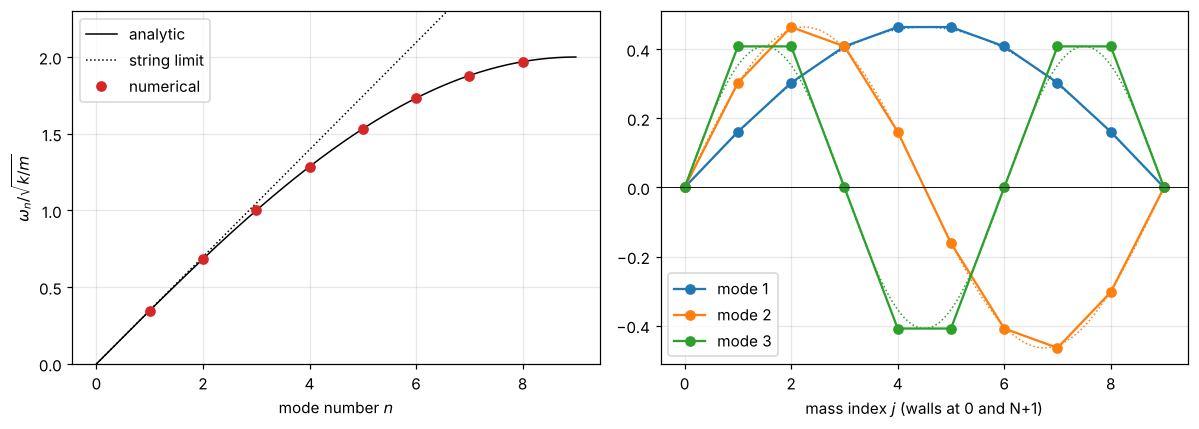

In [6]:
#| label: fig-chain
#| caption: Left, normal-mode frequencies of a chain of N = 8 masses (dots) from numerical diagonalization, on the analytic curve 2 sin(nπ/2(N+1)), with the continuous-string line ω ∝ n for comparison. Right, the first three mode shapes, which are samples of standing sine waves.
N = 8
K = (2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1))      # in units of k, with m = 1
w2, modes = np.linalg.eigh(K)
n = np.arange(1, N + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
nn = np.linspace(0, N + 1, 200)
axes[0].plot(nn, 2 * np.sin(nn * np.pi / (2 * (N + 1))), "k-", lw=1, label="analytic")
axes[0].plot(nn, nn * np.pi / (N + 1), "k:", lw=1, label="string limit")
axes[0].plot(n, np.sqrt(w2), "o", color="tab:red", label="numerical")
axes[0].set_xlabel("mode number $n$"); axes[0].set_ylabel(r"$\omega_n/\sqrt{k/m}$"); axes[0].set_ylim(0, 2.3)
axes[0].legend()
j = np.arange(0, N + 2)
for r, c in zip(range(3), ["tab:blue", "tab:orange", "tab:green"]):
    shape = np.r_[0, modes[:, r], 0]
    shape *= np.sign(shape[1])
    axes[1].plot(j, shape, "o-", color=c, label=f"mode {r + 1}")
    xs = np.linspace(0, N + 1, 200)
    axes[1].plot(xs, np.max(np.abs(shape)) * np.sin((r + 1) * np.pi * xs / (N + 1)), ":", color=c, lw=1)
axes[1].axhline(0, color="k", lw=0.6); axes[1].set_xlabel("mass index $j$ (walls at 0 and N+1)"); axes[1].legend()
plt.tight_layout(); plt.show()

## Driving a Coupled System

Drive the two-cart system with a force $\vec{F}\cos\omega t$. The steady state is $\vec{x} = (K - \omega^2M)^{-1}\vec{F}\cos\omega t$ (add damping to keep it finite). Expanding in modes, each mode responds like a single oscillator, weighted by how much of the force "overlaps" its shape, $\vec{a}_r\cdot\vec{F}$:

- Pushing only cart 1 overlaps both modes, so there are two resonance peaks.
- Pushing both carts equally in the same direction has **zero overlap** with the antisymmetric mode, and its resonance disappears entirely.

This is why the way a structure is driven matters as much as its natural frequencies.

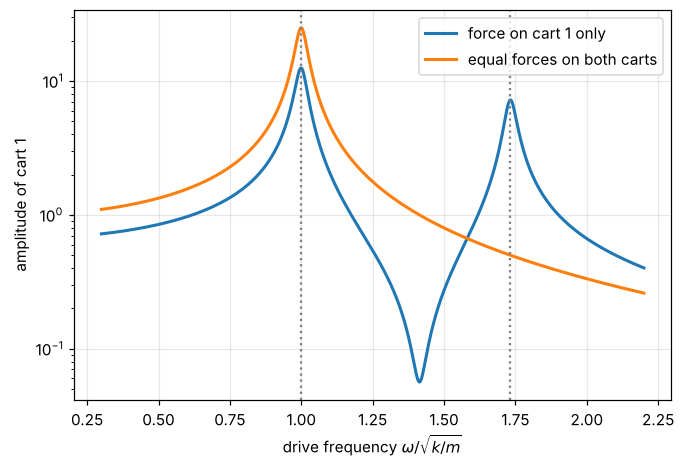

In [7]:
#| label: fig-coupled-drive
#| caption: Steady-state amplitude of cart 1 versus drive frequency, with light damping. A force on cart 1 alone excites both normal modes; equal in-phase forces on both carts excite only the symmetric mode.
m_, k_, gam = 1.0, 1.0, 0.04
M = np.eye(2) * m_; K = np.array([[2, -1], [-1, 2]]) * k_
w = np.linspace(0.3, 2.2, 1500)
fig, ax = plt.subplots()
for F, lab in [(np.array([1, 0]), "force on cart 1 only"), (np.array([1, 1]), "equal forces on both carts")]:
    amp = [abs(np.linalg.solve(K - wi**2 * M + 1j * gam * wi * M, F)[0]) for wi in w]
    ax.semilogy(w, amp, lw=2, label=lab)
for wr in [1, np.sqrt(3)]:
    ax.axvline(wr, color="gray", ls=":")
ax.set_xlabel(r"drive frequency $\omega/\sqrt{k/m}$"); ax.set_ylabel("amplitude of cart 1"); ax.legend()
plt.show()

### Exercises

1. Two carts of mass $m$ are joined wall–$k$–cart–$k'$–cart–$k$–wall. Find the normal frequencies and the beat period when $k'\ll k$.
2. Use {eq}`eq-chain-modes` to find the normal frequencies of three equal masses joined by four equal springs, and check by solving $\det(K - \omega^2M) = 0$.
3. Show that two modes with different frequencies are $M$-orthogonal: $\vec{a}_1^{\mathsf T}M\vec{a}_2 = 0$.

:::{dropdown} Hints
1. The modes are still $\langle1,1\rangle$ and $\langle1,-1\rangle$ by symmetry.
2. $N = 3$ and $n = 1, 2, 3$.
3. Write $K\vec{a}_r = \omega_r^2M\vec{a}_r$ for both modes and compute $\vec{a}_1^{\mathsf T}K\vec{a}_2$ two ways.
:::

:::{dropdown} Answers
1. $\omega_1 = \sqrt{k/m}$, $\omega_2 = \sqrt{(k + 2k')/m}$. For small $k'$, $\omega_2 - \omega_1\approx\frac{k'}{k}\sqrt{k/m}$, so the beat period is about $2\pi\frac{k}{k'}\sqrt{m/k}$.
2. $\omega^2 = (k/m)(2 - \sqrt2)$, $2k/m$, $(k/m)(2 + \sqrt2)$.
3. $\vec{a}_1^{\mathsf T}K\vec{a}_2 = \omega_2^2\vec{a}_1^{\mathsf T}M\vec{a}_2$ and, using symmetry, also $= \omega_1^2\vec{a}_1^{\mathsf T}M\vec{a}_2$. With $\omega_1\ne\omega_2$, $\vec{a}_1^{\mathsf T}M\vec{a}_2 = 0$.
:::

## Summary

- Near equilibrium, $T = \tfrac12\dot{\vec{q}}^{\mathsf T}M\dot{\vec{q}}$ and $U = \tfrac12\vec{q}^{\mathsf T}K\vec{q}$, so $M\ddot{\vec{q}} = -K\vec{q}$.
- Normal modes solve $(K - \omega^2M)\vec{a} = \vec{0}$; frequencies come from $\det(K - \omega^2M) = 0$.
- Normal coordinates decouple the system into independent oscillators; any motion is a superposition of modes.
- Close frequencies give beats and complete energy exchange between weakly coupled parts.
- A chain of $N$ masses has standing-wave modes that become the wave equation as $N\to\infty$.
- A driven system resonates at each mode frequency, weighted by the overlap of the force with that mode's shape.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.